# 10 — Compare classifier accuracy against human time
**Goal:** test whether the actual classifier learns better using fewer simulated human seconds.
This is a repeated **development evaluation**, using separate confidence-calibration and accuracy-evaluation images. Final-test images and test annotators remain reserved.

The study has 1000 runs: **10 strategies × 5 fatigue settings × 2 starting sizes × 10 seeds**.
Each run continues to a 2,400-second allowance, recording 300, 600, 1,200, and 2,400 seconds.
The human is simulated; the classifier is really retrained from its answers.
Code: [stage2.py](../src/eval/stage2.py), [al_loop.py](../src/learn/al_loop.py).

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0,str(project))
from src.eval.stage2 import default_options, sample_curve, comparison_tables, paired_accuracy
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png',dpi=150)
    plt.show()

## 1. Fix the comparisons before looking at the results
We compare QMDP with greedy, fatigue-blind, always verify, always 2-choice, always full, random question type, and random image sampling with full labels. The last method chooses random images; the other methods draw from their own top-500 uncertain candidates.

The five settings are no fatigue, Markov beta=1, Markov beta=2, FALCON beta=1, and lapse-plus-fatigue beta=1. Lambda is 1.0 bits per second, chosen by the lambda sweep (`scripts/run_lambda_sweep.py`) on training annotators and tuning seeds, never on this study. Greedy + rest pauses at a threshold tuned for each setting with the Stage-1 procedure on training people, instead of a fixed 2.0. QMDP's selection was still provisional when this study was run, because the complete Stage-1 factorial grid was pending; the full grid (`scripts/run_full_grid.py`) later confirmed QMDP. This notebook remains a development study; the final test is reported in notebook 11.

We chose **80% accuracy as the primary target** and 75% as a secondary target before this study, based on Notebook 02's clean-label learning curve. We do not move the goal after seeing which method wins. The two starting sizes are reported separately because their trusted initial labels have different amounts of information.

In [2]:
options=default_options()
(project / 'configs/stage2_settings.json').write_text(json.dumps(options,indent=2))
display(pd.Series(options,name='setting').to_frame())
seeds=list(range(42,52))
print('Seeds:',seeds)
print('Starting labelled sets: 50 and 200 images')

,setting
budgets_seconds,"[300, 600, 1200, 2400]"
session_seconds,600
retrain_every_answers,10
initial_epochs,200
update_epochs,10
initial_lr,0.05
update_lr,0.01
targets_percent,"[75.0, 80.0]"
seed_label_cost,excluded; identical trusted starting labels wi...
session_rule,fixed 600-human-second shifts; crossing answer...


Seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]
Starting labelled sets: 50 and 200 images


## 2. Run or load the repeated study
Saved results are reused. Set `RUN_STUDY=True` to run/resume explicitly.
The command uses six numerical workers with one CPU thread each, and saves each finished run separately. This makes interruptions resumable. A fresh study can take several minutes.
If code changes, rerun before treating older outputs as current evidence.

In [3]:
RUN_STUDY=True
latest_path=project / 'outputs/stage2_latest.json'
if RUN_STUDY or not latest_path.exists():
    completed=subprocess.run([sys.executable,'-u','scripts/run_stage2_development.py'],
        cwd=project,capture_output=True,text=True,check=True)
    print(completed.stdout)
latest=json.loads(latest_path.read_text())
folder=project / latest['folder']
config=json.loads((folder / 'config.json').read_text())
current_source=hashlib.sha256(b''.join(path.read_bytes() for path in sorted((project / 'src').rglob('*.py')))).hexdigest()
assert config['source_sha256']==current_source, 'Source changed: set RUN_STUDY=True to refresh the results.'
# Keep the model name 'None' as text rather than treating it as a missing value.
results=pd.read_csv(folder / 'all_runs.csv',keep_default_na=False)
expected_runs=len(config['policies'])*len(config['scenarios'])*len(config['seed_sizes'])*len(config['seeds'])
assert len(results)==expected_runs and not results.final_test_evaluated.any()
print('Completed runs:',len(results),'| results folder:',folder)

Greedy-plus-rest thresholds: {'None beta=0': 1.0, 'Markov beta=1': 1.5, 'Markov beta=2': 1.0, 'FALCON beta=1': 3.0, 'Lapse beta=1': 1.5}
Completed 20/1000 classifier runs
Completed 40/1000 classifier runs
Completed 60/1000 classifier runs
Completed 80/1000 classifier runs
Completed 100/1000 classifier runs
Completed 120/1000 classifier runs
Completed 140/1000 classifier runs
Completed 160/1000 classifier runs
Completed 180/1000 classifier runs
Completed 200/1000 classifier runs
Completed 220/1000 classifier runs
Completed 240/1000 classifier runs
Completed 260/1000 classifier runs
Completed 280/1000 classifier runs
Completed 300/1000 classifier runs
Completed 320/1000 classifier runs
Completed 340/1000 classifier runs
Completed 360/1000 classifier runs
Completed 380/1000 classifier runs
Completed 400/1000 classifier runs
Completed 420/1000 classifier runs
Completed 440/1000 classifier runs
Completed 460/1000 classifier runs
Completed 480/1000 classifier runs
Completed 500/1000 classifi

## 3. Check pairing, budgets, and coverage
Every policy in a pair has the same initial pictures and initial weights. Human identities change on the same 600-second clock. Candidate and human random streams are matched where possible, but actual image rankings diverge as classifiers learn differently.
Scores at a budget use the last model trained by that time; they never use a later response.

In [4]:
pairs=results.groupby(['model','beta','seed_size','seed'])
assert pairs.policy.nunique().eq(len(config['policies'])).all()
assert (pairs.initial_accuracy.max()-pairs.initial_accuracy.min()).abs().max()<1e-6
assert (results.spent_seconds<=2400+1e-8).all()
assert not results.duplicated(['model','beta','seed_size','seed','policy']).any()
display(results.groupby(['model','beta','seed_size']).agg(runs=('policy','size'),seeds=('seed','nunique')))
print('Pairing and budget checks passed.')
assert results[['model','beta','seed_size']].drop_duplicates().shape[0]==10

runs  seeds
model  beta seed_size             
FALCON 1    50          100     10
            200         100     10
Lapse  1    50          100     10
            200         100     10
Markov 1    50          100     10
            200         100     10
       2    50          100     10
            200         100     10
None   0    50          100     10
            200         100     10

Pairing and budget checks passed.


## 4. Put every learning curve on the same time scale
At each second-grid point, use the latest earlier training result. This produces fair averages even though policies retrain at different human times.
A run that exhausts the pool keeps its last accuracy and reports unused allowance.

In [5]:
time_grid=np.unique(np.r_[np.arange(0,2401,60),300,600,1200,2400])
rows=[]
for _,run in results.iterrows():
    curve=pd.read_csv(project / run.run_folder / 'accuracy_curve.csv')
    accuracy=sample_curve(curve,time_grid)
    for seconds,value in zip(time_grid,accuracy):
        rows.append({'model':run.model,'beta':run.beta,'seed_size':run.seed_size,'seed':run.seed,
            'policy':run.policy,'seconds':seconds,'accuracy_percent':value})
curves=pd.DataFrame(rows)
curves.to_csv(folder / 'curves_on_common_time_grid.csv.gz',index=False)
names={'qmdp':'QMDP','qmdp_fixed':'QMDP (fixed model)','myopic':'Greedy','rest_threshold':'Greedy + rest','blind':'Ignores fatigue','verify':'Always verify',
    'two_choice':'Always 2-choice','full':'Always full','random':'Random type','random_image_full':'Random image + full'}
colors=dict(zip(names,['#238b45','#74c476','#2171b5','#6baed6','#969696','#a6761d','#e6ab02','#cb181d','#984ea3','#fb6a4a']))
conditions=[('None',0),('Markov',1),('Markov',2),('FALCON',1),('Lapse',1)]

## 5. Compare accuracy versus human seconds
Each line averages ten seeds. QMDP is highlighted in green. The two starting sizes get separate figures; starting with 200 trusted labels should not be confused with starting with 50 at the same total labelling cost.

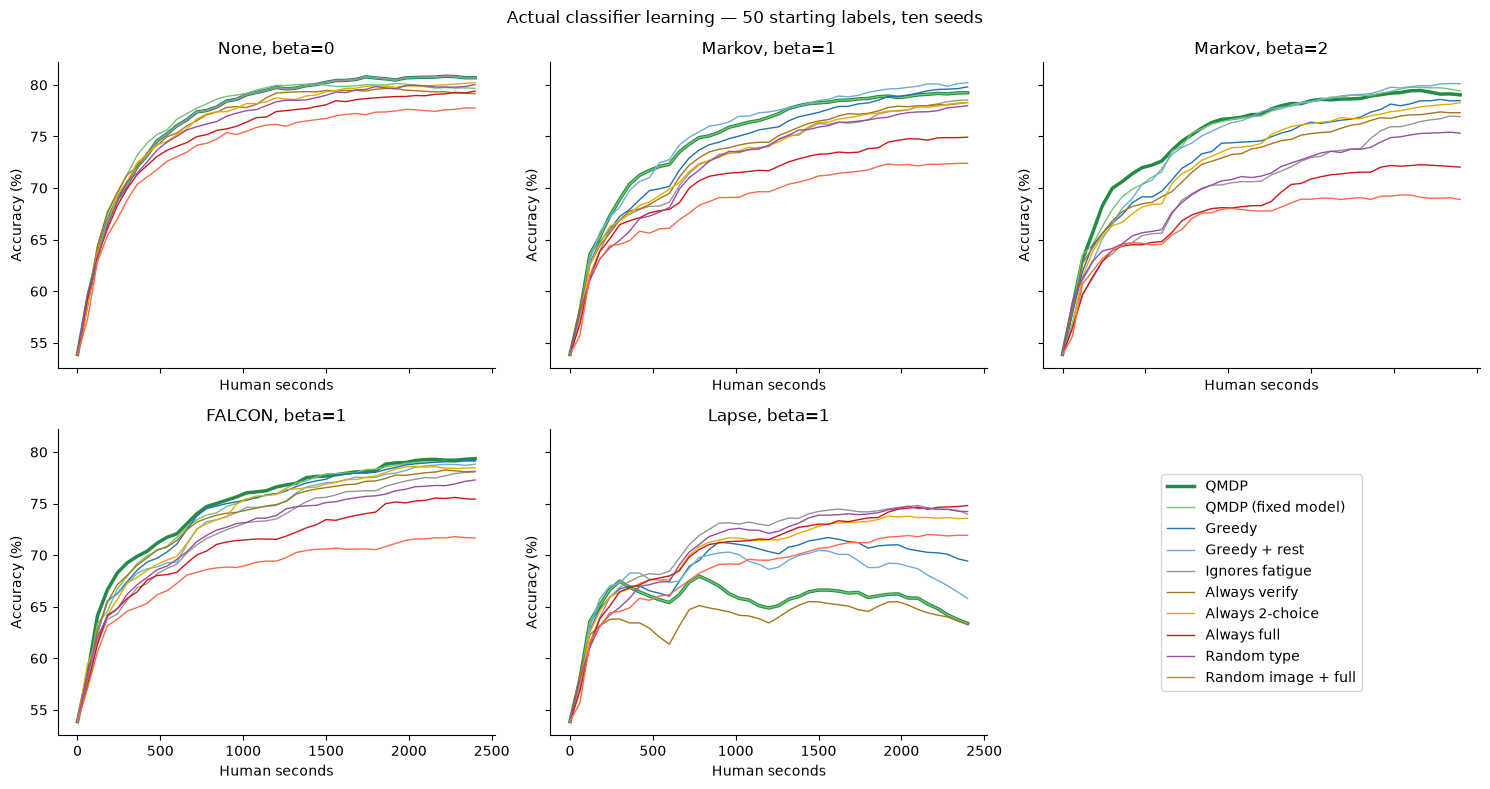

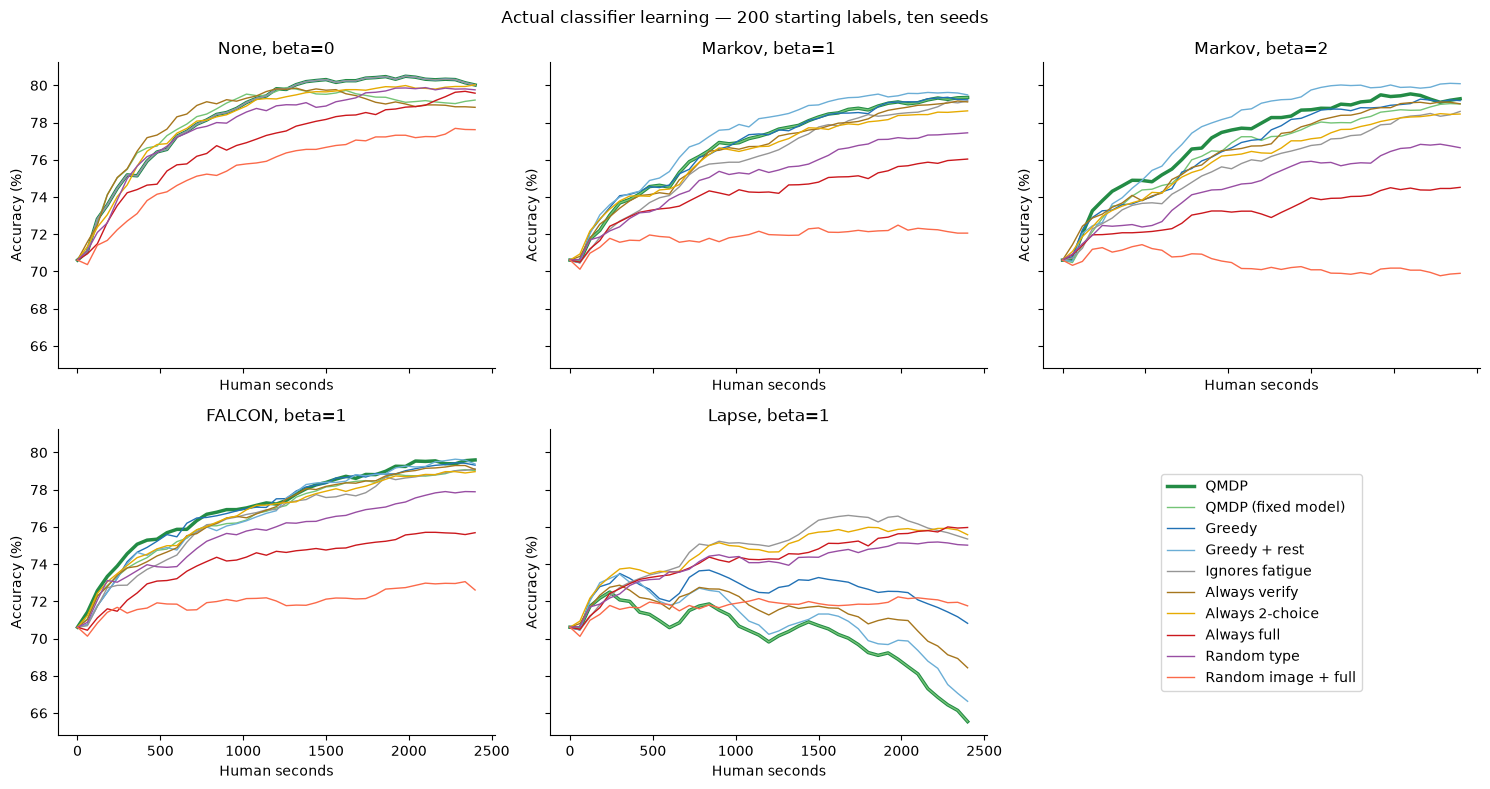

In [6]:
for size in [50,200]:
    fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True,sharey=True)
    for ax,(model,beta) in zip(axes.flat,conditions):
        subset=curves[(curves.seed_size==size)&curves.model.eq(model)&curves.beta.eq(beta)]
        for policy in names:
            mean=subset[subset.policy==policy].groupby('seconds').accuracy_percent.mean()
            ax.plot(mean.index,mean,label=names[policy],color=colors[policy],linewidth=2.5 if policy=='qmdp' else 1)
        ax.set(title=f'{model}, beta={beta}',xlabel='Human seconds',ylabel='Accuracy (%)')
    handles,labels=axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].axis('off')
    axes.flat[-1].legend(handles,labels,loc='center')
    fig.suptitle(f'Actual classifier learning — {size} starting labels, ten seeds')
    show_plot(f'01_accuracy_curves_{size}_starting_labels')

## 6. Compare overall learning and final accuracy
**Area under the curve** here means average accuracy across 0–2,400 human seconds.
It rewards learning sooner, not only ending well. We use this as the summary for choosing the strongest comparison strategy on development data. All numerical comparisons remain available.

,model,beta,seed_size,policy,average_accuracy,final_accuracy,final_accuracy_se,label_error_rate,answers,target_80_reached
0,FALCON,1,50,blind,72.362,78.07,0.266,0.075,1129.0,0
1,FALCON,1,50,full,70.928,75.43,0.518,0.192,560.0,0
2,FALCON,1,50,myopic,74.152,79.16,0.297,0.051,1736.9,3
3,FALCON,1,50,qmdp,74.767,79.37,0.400,0.044,1906.6,5
4,FALCON,1,50,qmdp_fixed,74.307,79.11,0.157,0.044,1812.1,3
...,...,...,...,...,...,...,...,...,...,...
95,None,0,200,random,77.852,79.76,0.258,0.032,2085.8,6
96,None,0,200,random_image_full,75.523,77.62,0.254,0.043,1348.2,0
97,None,0,200,rest_threshold,78.371,80.02,0.250,0.017,3336.6,10
98,None,0,200,two_choice,78.133,80.03,0.272,0.025,2269.8,10


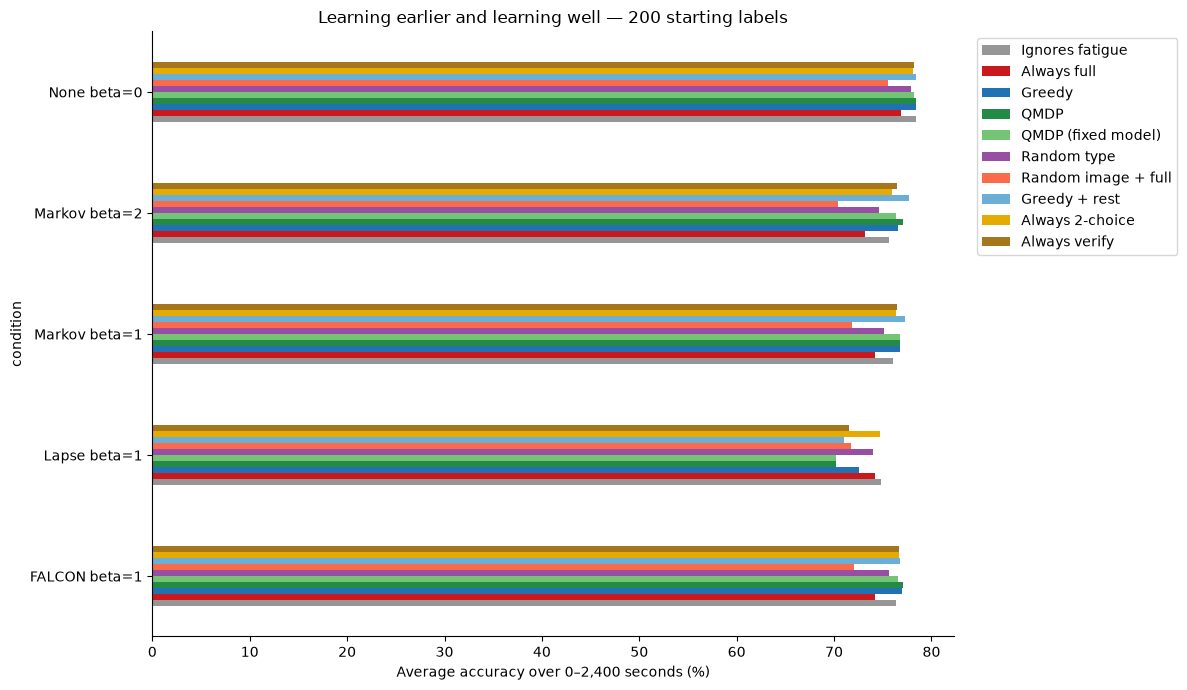

In [7]:
summary=results.groupby(['model','beta','seed_size','policy']).agg(
    average_accuracy=('auc_accuracy_percent','mean'),final_accuracy=('accuracy_2400s','mean'),
    final_accuracy_se=('accuracy_2400s','sem'),label_error_rate=('acquired_error_rate','mean'),
    answers=('acquired_answers','mean'),target_80_reached=('reached_80','sum')).reset_index()
summary.to_csv(folder / 'condition_summary.csv',index=False)
display(summary.round(3))
shown=summary[summary.seed_size==200].copy()
shown['condition']=shown.model+' beta='+shown.beta.astype(str)
average_table=shown.pivot(index='condition',columns='policy',values='average_accuracy')
average_table.rename(columns=names).plot.barh(figsize=(12,7),color=[colors[name] for name in average_table.columns])
plt.xlabel('Average accuracy over 0–2,400 seconds (%)')
plt.title('Learning earlier and learning well — 200 starting labels')
plt.legend(bbox_to_anchor=(1.02,1),loc='upper left')
show_plot('02_average_accuracy_over_time')

## 7. Compare paired accuracy differences
Subtract each comparison method from QMDP within the same seed, then bootstrap the ten paired differences. Positive means QMDP has higher accuracy.
These are pointwise, unadjusted 95% intervals used for exploratory development.
Strongest-baseline selection uses these validation runs too, so it is not independent confirmation.

In [8]:
accuracy_pairs,target_pairs=comparison_tables(results)
accuracy_pairs.to_csv(folder / 'paired_accuracy_comparisons.csv',index=False)
target_pairs.to_csv(folder / 'paired_target_time_comparisons.csv',index=False)
main_pairs=accuracy_pairs[(accuracy_pairs.seed_size==200)&accuracy_pairs.budget.eq(2400)&accuracy_pairs.second.isin(['verify','blind','myopic'])]
display(main_pairs[['model','beta','second','difference','ci_low','ci_high']].round(3))
strongest=[]
for key,group in results.groupby(['model','beta','seed_size']):
    # Review fix: the fixed-model QMDP is a QMDP variant, not a baseline.
    baseline=group[~group.policy.isin(['qmdp','qmdp_fixed'])].groupby('policy').auc_accuracy_percent.mean().idxmax()
    strongest.append({'model':key[0],'beta':key[1],'seed_size':key[2],'baseline':baseline,
        **paired_accuracy(group,'auc_accuracy_percent','qmdp',baseline)})
strongest=pd.DataFrame(strongest)
strongest.to_csv(folder / 'qmdp_vs_strongest_baseline.csv',index=False)
display(strongest.round(3))

,model,beta,second,difference,ci_low,ci_high
39,FALCON,1,blind,0.48,-0.44,1.28
47,FALCON,1,myopic,0.28,-0.25,0.87
71,FALCON,1,verify,0.51,-0.04,0.98
111,Lapse,1,blind,-9.81,-11.34,-8.23
119,Lapse,1,myopic,-5.28,-7.15,-3.49
143,Lapse,1,verify,-2.89,-4.54,-1.29
183,Markov,1,blind,0.19,-0.68,1.23
191,Markov,1,myopic,0.13,-0.73,1.01
215,Markov,1,verify,0.24,-0.47,0.95
255,Markov,2,blind,0.68,-0.05,1.33


,model,beta,seed_size,baseline,first,second,metric,difference,ci_low,ci_high,pairs
0,FALCON,1,50,myopic,qmdp,myopic,auc_accuracy_percent,0.615,-0.411,1.658,10
1,FALCON,1,200,myopic,qmdp,myopic,auc_accuracy_percent,0.171,-0.243,0.579,10
2,Lapse,1,50,blind,qmdp,blind,auc_accuracy_percent,-5.763,-7.421,-3.991,10
3,Lapse,1,200,blind,qmdp,blind,auc_accuracy_percent,-4.674,-5.447,-3.847,10
4,Markov,1,50,rest_threshold,qmdp,rest_threshold,auc_accuracy_percent,-0.347,-0.800,0.115,10
5,Markov,1,200,rest_threshold,qmdp,rest_threshold,auc_accuracy_percent,-0.574,-1.149,0.048,10
6,Markov,2,50,rest_threshold,qmdp,rest_threshold,auc_accuracy_percent,0.525,-0.037,1.084,10
7,Markov,2,200,rest_threshold,qmdp,rest_threshold,auc_accuracy_percent,-0.523,-0.972,0.011,10
8,None,0,50,blind,qmdp,blind,auc_accuracy_percent,0.000,0.000,0.000,10
9,None,0,200,blind,qmdp,blind,auc_accuracy_percent,0.000,0.000,0.000,10


## 8. Plot the average-accuracy advantage over the strongest comparison
Each point represents one fatigue setting and starting size. Error bars show the paired uncertainty. Values left of zero are useful negative results, not something to hide.

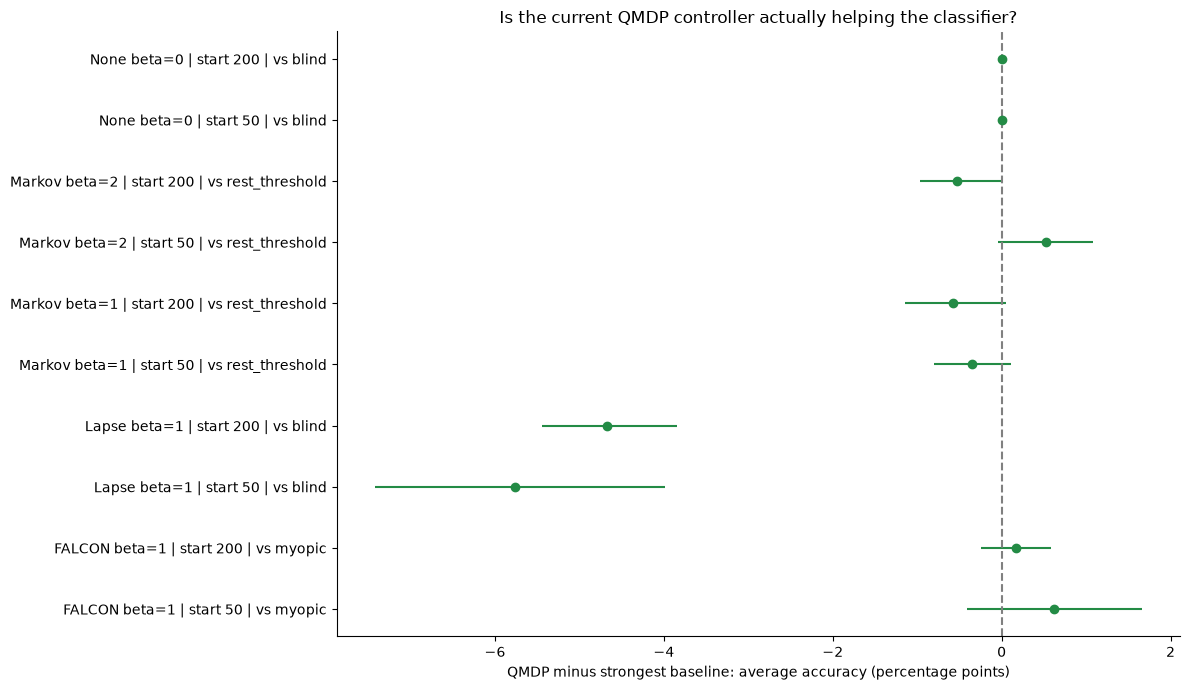

In [9]:
labels=strongest.model+' beta='+strongest.beta.astype(str)+' | start '+strongest.seed_size.astype(str)+' | vs '+strongest.baseline
plt.figure(figsize=(12,7))
plt.errorbar(strongest.difference,labels,xerr=np.array([strongest.difference-strongest.ci_low,
    strongest.ci_high-strongest.difference]),fmt='o',color='#238b45')
plt.axvline(0,color='gray',linestyle='--')
plt.xlabel('QMDP minus strongest baseline: average accuracy (percentage points)')
plt.title('Is the current QMDP controller actually helping the classifier?')
show_plot('03_paired_average_accuracy_advantage')

## 9. Count who actually reaches 80% accuracy
If a run never reaches 80%, its true time-to-target is unknown beyond the budget.
We record **not reached** and cap time at 2,400 seconds for a restricted-window summary.
That cap must not be described as the actual time needed to reach 80%.
The target means first observed attainment after a retrain, not guaranteed permanent attainment.

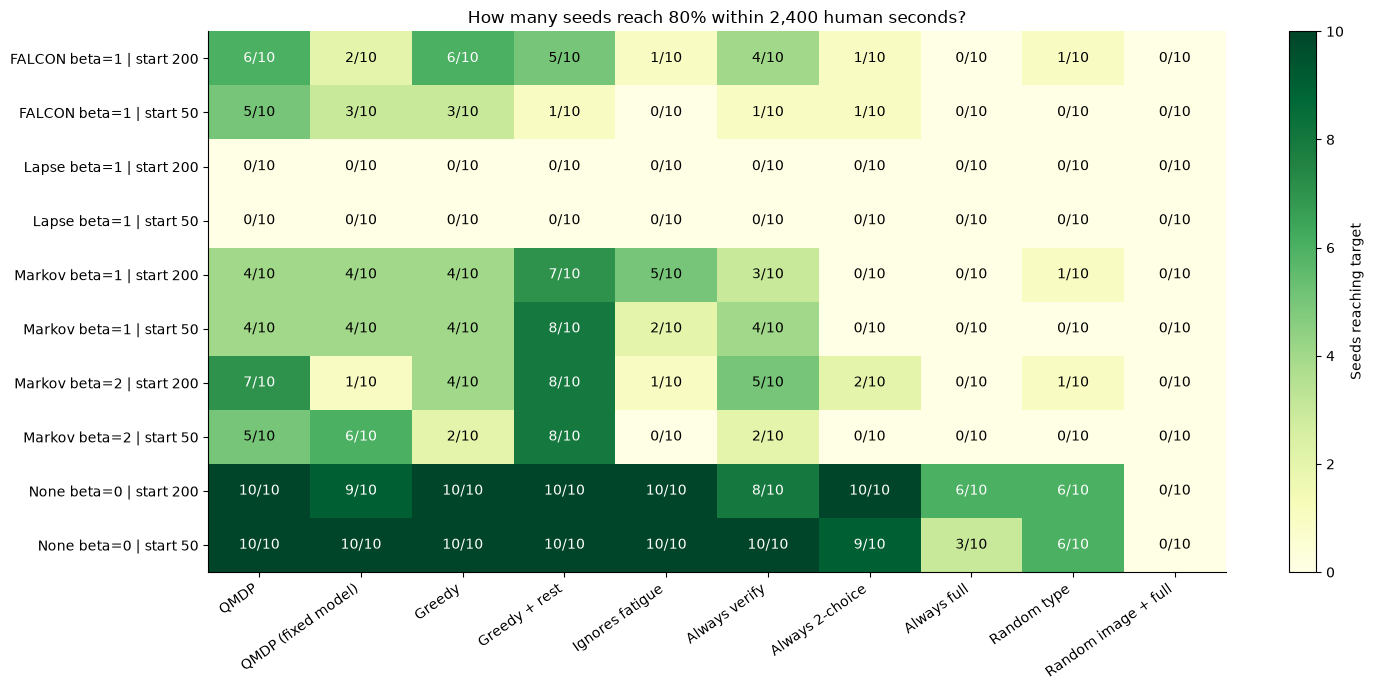

In [10]:
target_summary=results.groupby(['model','beta','seed_size','policy']).agg(
    reached=('reached_80','sum'),capped_mean_seconds=('time_80_capped','mean')).reset_index()
target_summary['condition']=target_summary.model+' beta='+target_summary.beta.astype(str)+' | start '+target_summary.seed_size.astype(str)
target_summary.to_csv(folder / 'target_80_summary.csv',index=False)
reach=target_summary.pivot(index='condition',columns='policy',values='reached').reindex(columns=list(names))
count=reach.shape[1]  # number of policies (10 now), instead of a fixed 8
fig,ax=plt.subplots(figsize=(1.3*count+2,7))
image=ax.imshow(reach,cmap='YlGn',vmin=0,vmax=10,aspect='auto')
ax.set_xticks(range(count),[names[name] for name in reach.columns],rotation=35,ha='right')
ax.set_yticks(range(len(reach)),reach.index)
for row in range(len(reach)):
    for column in range(count):
        ax.text(column,row,f'{int(reach.iloc[row,column])}/10',ha='center',va='center',color='white' if reach.iloc[row,column]>=6 else 'black')
ax.set_title('How many seeds reach 80% within 2,400 human seconds?')
fig.colorbar(image, ax=ax,label='Seeds reaching target')
show_plot('04_target_accuracy_reach_counts')

## 10. Quantify time savings only where the target is observed in every paired run
We show capped-window comparisons for all settings. A conventional percentage of time saved is reported only if both policies reach 80% in all ten seeds and the baseline takes positive time. Otherwise it stays missing; we do not average only the lucky successful runs.

In [11]:
time_rows=[]
for _,comparison in strongest.iterrows():
    group=results[results.model.eq(comparison.model)&results.beta.eq(comparison.beta)&results.seed_size.eq(comparison.seed_size)]
    q=group[group.policy=='qmdp'].set_index('seed')
    baseline=group[group.policy==comparison.baseline].set_index('seed')
    complete=bool(q.reached_80.all() and baseline.reached_80.all())
    saving=(baseline.time_80_capped.mean()-q.time_80_capped.mean())/baseline.time_80_capped.mean()*100 if complete and baseline.time_80_capped.mean()>0 else np.nan
    time_rows.append({'model':comparison.model,'beta':comparison.beta,'seed_size':comparison.seed_size,
        'baseline':comparison.baseline,'qmdp_reached':int(q.reached_80.sum()),'baseline_reached':int(baseline.reached_80.sum()),
        'qmdp_capped_seconds':q.time_80_capped.mean(),'baseline_capped_seconds':baseline.time_80_capped.mean(),
        'fully_observed_time_saving_percent':saving})
time_comparison=pd.DataFrame(time_rows)
time_comparison.to_csv(folder / 'time_to_target_vs_strongest.csv',index=False)
display(time_comparison.round(2))

,model,beta,seed_size,baseline,qmdp_reached,baseline_reached,qmdp_capped_seconds,baseline_capped_seconds,fully_observed_time_saving_percent
0,FALCON,1,50,myopic,5,3,2187.05,2300.83,NaN
1,FALCON,1,200,myopic,6,6,1982.65,2019.77,NaN
2,Lapse,1,50,blind,0,0,2400.00,2400.00,NaN
3,Lapse,1,200,blind,0,0,2400.00,2400.00,NaN
4,Markov,1,50,rest_threshold,4,8,2270.38,1945.28,NaN
5,Markov,1,200,rest_threshold,4,7,2163.83,1811.93,NaN
6,Markov,2,50,rest_threshold,5,8,1934.47,2007.47,NaN
7,Markov,2,200,rest_threshold,7,8,1986.64,1573.01,NaN
8,None,0,50,blind,10,10,1247.03,1247.03,0.0
9,None,0,200,blind,10,10,1177.31,1177.31,0.0


## 10b. Report the predeclared secondary 75% target too
The primary target remains 80%. We also declared 75% before running the study.
This lower target can provide fully observed paired times when some methods never reach 80%.
We report it for every condition, including cases where QMDP is slower. Positive seconds saved favours QMDP. A percentage stays missing when either method misses the target in any seed.

In [12]:
secondary_rows=[]
for _,comparison in strongest.iterrows():
    group=results[results.model.eq(comparison.model)&results.beta.eq(comparison.beta)&results.seed_size.eq(comparison.seed_size)]
    q=group[group.policy=='qmdp'].set_index('seed')
    baseline=group[group.policy==comparison.baseline].set_index('seed')
    complete=bool(q.reached_75.all() and baseline.reached_75.all())
    mean_q,mean_baseline=q.time_75_capped.mean(),baseline.time_75_capped.mean()
    saving=(mean_baseline-mean_q)/mean_baseline*100 if complete and mean_baseline>0 else np.nan
    interval=paired_accuracy(group,'time_75_capped',comparison.baseline,'qmdp')
    secondary_rows.append({'model':comparison.model,'beta':comparison.beta,'seed_size':comparison.seed_size,
        'baseline':comparison.baseline,'qmdp_reached':int(q.reached_75.sum()),'baseline_reached':int(baseline.reached_75.sum()),
        'qmdp_capped_seconds':mean_q,'baseline_capped_seconds':mean_baseline,
        'fully_observed_time_saving_percent':saving,'seconds_saved_ci_low':interval['ci_low'],'seconds_saved_ci_high':interval['ci_high']})
secondary_times=pd.DataFrame(secondary_rows)
secondary_times.to_csv(folder / 'secondary_target_75_comparisons.csv',index=False)
display(secondary_times.round(2))

,model,beta,seed_size,baseline,qmdp_reached,baseline_reached,qmdp_capped_seconds,baseline_capped_seconds,fully_observed_time_saving_percent,seconds_saved_ci_low,seconds_saved_ci_high
0,FALCON,1,50,myopic,10,10,809.16,897.16,9.81,-153.35,299.07
1,FALCON,1,200,myopic,10,10,437.12,426.58,-2.47,-94.39,67.46
2,Lapse,1,50,blind,1,7,2189.49,1666.27,NaN,-894.69,-150.31
3,Lapse,1,200,blind,3,10,1790.42,956.05,NaN,-1333.46,-312.07
4,Markov,1,50,rest_threshold,10,10,806.08,737.77,-9.26,-234.16,87.74
5,Markov,1,200,rest_threshold,10,10,521.54,453.02,-15.13,-226.83,74.23
6,Markov,2,50,rest_threshold,10,10,694.41,781.48,11.14,-8.13,172.25
7,Markov,2,200,rest_threshold,10,10,465.94,487.65,4.45,-57.84,97.02
8,None,0,50,blind,10,10,472.94,472.94,0.00,0.00,0.00
9,None,0,200,blind,10,10,271.72,271.72,0.00,0.00,0.00


## 11. Check label noise, acquired answers, and calibration limits
These help explain performance. They are not inputs to the learner's policy.
A confidence-grid boundary flag marks a last-retrain calibration optimum at the search limit.
It is a diagnostic, especially for badly corrupted models, rather than evidence of good calibration.

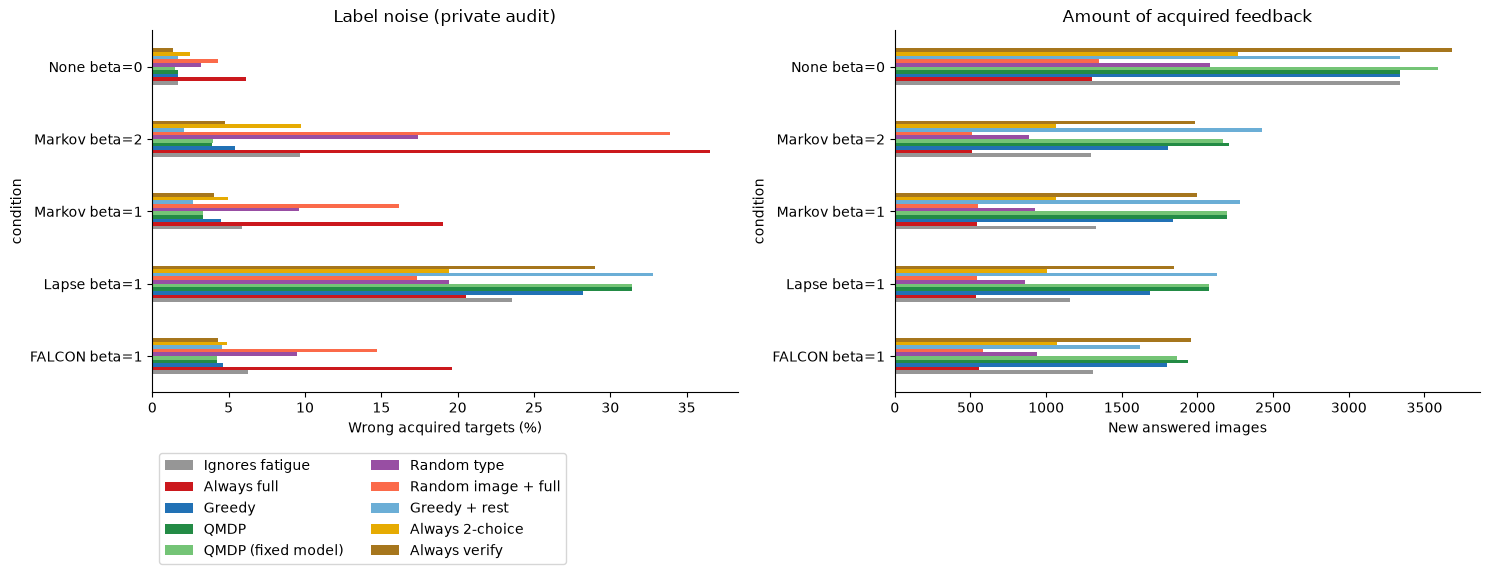

,calibration_boundary_runs,pool_exhausted_runs
policy,,
blind,0,4
full,0,0
myopic,0,4
qmdp,0,4
qmdp_fixed,0,9
random,0,0
random_image_full,0,0
rest_threshold,0,4
two_choice,0,0


In [13]:
shown=summary[summary.seed_size==200].copy()
shown['condition']=shown.model+' beta='+shown.beta.astype(str)
fig,axes=plt.subplots(1,2,figsize=(15,6))
noise_table=shown.pivot(index='condition',columns='policy',values='label_error_rate').mul(100)
noise_table.rename(columns=names).plot.barh(ax=axes[0],color=[colors[name] for name in noise_table.columns])
answer_table=shown.pivot(index='condition',columns='policy',values='answers')
answer_table.rename(columns=names).plot.barh(ax=axes[1],legend=False,color=[colors[name] for name in answer_table.columns])
axes[0].set(xlabel='Wrong acquired targets (%)',title='Label noise (private audit)')
axes[1].set(xlabel='New answered images',title='Amount of acquired feedback')
axes[0].legend(bbox_to_anchor=(0,-.15),loc='upper left',ncol=2)
show_plot('05_label_noise_and_answer_counts')
display(results.groupby('policy').agg(calibration_boundary_runs=('temperature_boundary','sum'),pool_exhausted_runs=('pool_exhausted','sum')))

## 11b. Did any rare lapse actually occur? (Outdated: old rare lapse)
A rare-event setting is not evidence about disengagement if no acquired answer happened after a lapse.
We reconstruct the saved experiment's deterministic onset tapes for evaluation only.
This works because the configured lapse-onset hazard is constant (dependence on fatigue is zero).
These private tapes never go to the learner or controller. The onset occurs after that step's answer.

In [14]:
# Review fix: lapses are now forced once per shift, and the private audit records whether each
# answer was given while disengaged, so coverage is read directly instead of replayed.
coverage_rows=[]
for _,run in results[results.model=='Lapse'].iterrows():
    events=pd.read_csv(project / run.run_folder / 'answer_audit.csv.gz')
    affected=int((events.lapsed & events.accepted & events.action.isin([1,2,3])).sum())
    coverage_rows.append({'seed':run.seed,'seed_size':run.seed_size,'policy':run.policy,'answers_after_lapse':affected,
        'answers':int((events.accepted & events.action.isin([1,2,3])).sum())})
lapse_coverage=pd.DataFrame(coverage_rows)
lapse_coverage.to_csv(folder / 'lapse_event_coverage.csv',index=False)
display(lapse_coverage.groupby('policy')[['answers_after_lapse','answers']].sum())
assert lapse_coverage.answers_after_lapse.sum()>0, 'No answers were collected during a lapse; the Lapse setting is untested.'

,answers_after_lapse,answers
policy,,
blind,7298,21901
full,250,10675
myopic,16784,32879
qmdp,25316,41436
qmdp_fixed,25316,41436
random,3506,17966
random_image_full,263,10923
rest_threshold,25567,41687
two_choice,5114,20383


## 12. Save the project assessment, including unfavorable results
The repeated development study can tell us whether the current implementation is promising and where it fails. It cannot establish real-human time savings or final held-out performance.
Keep the full Stage-1 sweep, frozen selection, and final reporting separate from this exploration.

*Update (22 Nov): the full Stage-1 sweep, the frozen selection and the final reporting have since been done (`scripts/run_full_grid.py`, `scripts/run_final_test.py`, notebook 11). The assessment below is kept exactly as it was saved for this development study; its "full Stage-1 factorial sweep pending" entry describes the state at that time.*

In [15]:
assessment={'status':'preliminary Stage-2 development study','classifier_runs':len(results),'seeds_per_pair':10,
    'comparison_groups':len(strongest),'qmdp_positive_average_accuracy_intervals':int((strongest.ci_low>0).sum()),
    'qmdp_negative_average_accuracy_intervals':int((strongest.ci_high<0).sum()),
    'groups_with_fully_observed_80_percent_target':int(time_comparison.fully_observed_time_saving_percent.notna().sum()),
    'groups_with_fully_observed_75_percent_target':int(secondary_times.fully_observed_time_saving_percent.notna().sum()),
    'acquired_answers_after_rare_lapse':int(lapse_coverage.answers_after_lapse.sum()),
    'final_test_images_evaluated':False,'test_annotators_evaluated':False,
    'limitations':['simulated humans','development comparisons after provisional selection','pointwise unadjusted intervals',
        '600-second shifts and capped practice are assumptions','full Stage-1 factorial sweep pending','rare-lapse robustness requires checking realized event coverage']}
(folder / 'assessment.json').write_text(json.dumps(assessment,indent=2))
display(pd.Series(assessment,name='finding').to_frame())
print('Open qmdp_vs_strongest_baseline.csv and time_to_target_vs_strongest.csv for the key comparisons.')

,finding
status,preliminary Stage-2 development study
classifier_runs,1000
seeds_per_pair,10
comparison_groups,10
qmdp_positive_average_accuracy_intervals,0
qmdp_negative_average_accuracy_intervals,2
groups_with_fully_observed_80_percent_target,2
groups_with_fully_observed_75_percent_target,8
acquired_answers_after_rare_lapse,130635
final_test_images_evaluated,False


Open qmdp_vs_strongest_baseline.csv and time_to_target_vs_strongest.csv for the key comparisons.
